**“Social Media Engagement Analytics”**

Dataset Provided:
social_media_engagement_5000.csv

**❖Task 1 — Data Import & Setup**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Import CSV using Pandas**

In [2]:
from google.colab import files

uploaded = files.upload()

Saving social_media_engagement_5000.csv to social_media_engagement_5000.csv


In [3]:
df = pd.read_csv("social_media_engagement_5000.csv")

**Check/convert data types**

In [4]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


**Convert date columns to datetime**

In [6]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

In [7]:
df['posted_at'] = pd.to_datetime(df['posted_at'])

/tmp/ipykernel_2769/1302919506.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['posted_at'] = pd.to_datetime(df['posted_at'])


In [8]:
df["posted_at"].head()

,posted_at
0,2022-12-17
1,2023-06-02
2,2023-05-07
3,2023-02-12
4,2023-05-23


**use NumPy arrays for basic array operations**

In [9]:
likes = np.array(df["likes"])

print("First 10 likes:", likes[:10])
print("Total likes:", np.sum(likes))
print("Average likes:", np.mean(likes))
print("Maximum likes:", np.max(likes))
print("Minimum likes:", np.min(likes))

First 10 likes: [ 7011. 11750.  4862.  5350. 12682. 12535. 11703.  9611.    nan 14106.]
Total likes: nan
Average likes: nan
Maximum likes: nan
Minimum likes: nan


**❖Task 2 — Data Cleaning**

**● Cleaning Missing Data**

**■Detect missing values (isnull(), isna())**

In [10]:
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


In [11]:
df.isna().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


**■Handle using: dropna(), fillna(), median/mode, forward/backward-fill**

In [12]:
df_cleaned = df.dropna()

In [13]:
df['sentiment'] = df['sentiment'].fillna('Unknown')

In [14]:
num_cols = df.select_dtypes(include="number").columns

print(num_cols)

Index(['user_id', 'age', 'post_id', 'likes', 'comments', 'shares',
       'watch_time_sec', 'impression_count', 'follower_count',
       'engagement_rate'],
      dtype='object')


In [15]:
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [16]:
cat_cols = df.select_dtypes(include=["object", "category"]).columns

print(cat_cols)

Index(['gender', 'country', 'post_type', 'post_category', 'device_type',
       'sentiment', 'hashtags'],
      dtype='object')


In [17]:
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

In [18]:
df_forward = df.ffill()

display(df_forward.head())

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372


In [19]:
df_backward = df.bfill()

display(df_backward.head())

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372


In [20]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


**●Duplicate Handling**

**■Identify & remove duplicates**

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df = df.drop_duplicates()

print(df.shape)

(5000, 19)


**●Data Formatting**

**■Fix incorrect data types**

In [23]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


In [24]:
df["likes"] = pd.to_numeric(df["likes"], errors="coerce")

df["comments"] = pd.to_numeric(df["comments"], errors="coerce")

df["shares"] = pd.to_numeric(df["shares"], errors="coerce")

In [25]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


■**Standardize categories (e.g., gender labels)**

In [26]:
df["gender"] = df["gender"].str.strip().str.lower()
df["gender"].value_counts()


,count
gender,
male,1849
other,1581
female,1570


In [27]:
df["post_type"] = df["post_type"].str.strip().str.lower()
df["post_type"].value_counts()

,count
post_type,
reel,1283
image,1247
text,1245
video,1225


In [28]:
df["post_category"] = df["post_category"].str.strip().str.lower()
df["post_category"].value_counts()

,count
post_category,
fitness,675
tech,665
music,635
education,631
lifestyle,607
travel,600
fashion,594
food,593


In [29]:
df["device_type"] = df["device_type"].str.strip().str.lower()
df["device_type"].value_counts()

,count
device_type,
mobile,1684
tablet,1658
desktop,1658


**■Correct unrealistic values in likes, comments, shares**

In [30]:
print("Negative likes:", (df["likes"] < 0).sum())

print("Negative comments:", (df["comments"] < 0).sum())

print("Negative shares:", (df["shares"] < 0).sum())

Negative likes: 0
Negative comments: 0
Negative shares: 0


**● Feature Cleaning**

**■Extract hashtag count**

In [31]:
df["hashtag_count"] = df["hashtags"].fillna("").apply(
    lambda x: len([tag for tag in x.split() if tag.startswith("#")])
)

**■Clean sentiment labels**

In [32]:
df["sentiment"] = df["sentiment"].str.strip().str.lower()
df["sentiment"].value_counts()

,count
sentiment,
positive,2363
neutral,1527
negative,960
unknown,150


**❖Task 3 — Data Exploration using Pandas**

**●View dataset structure using head(), tail(), shape, and columns.**

In [33]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


In [34]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,USA,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [35]:
df.shape

(5000, 20)

In [36]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')

**●Check data types and info with info() and dtypes.**

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [38]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


**●Generate summary statistics using describe().**

In [39]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


**●Analyze categorical distributions using value_counts(), unique(), and nunique().**

In [40]:
df["post_type"].value_counts()

,count
post_type,
reel,1283
image,1247
text,1245
video,1225


In [41]:
df["post_type"].unique()

array(['image', 'reel', 'text', 'video'], dtype=object)

In [42]:
df["post_type"].nunique()

4

**●Create a correlation matrix for numeric fields.**

In [43]:
correlation = df.select_dtypes(include="number").corr()

display(correlation)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


**●Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).**

In [44]:
df.groupby("post_type")["likes"].mean()

,likes
post_type,
image,10104.865277
reel,10037.802416
text,10100.148193
video,10188.600000


In [45]:
print(df.groupby('country')['impression_count'].mean())

country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64


**Task 4 — Data Wrangling**

**●Use merge, concat, or join if combining DataFrames.**

**●Create new fields such as engagement_score, log-transformed metrics (optional), and hashtag_count.**

In [46]:
df["engagement_score"] = (
    df["likes"] + df["comments"] + df["shares"]
)

display(df[["likes", "comments", "shares", "engagement_score"]].head())

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


In [47]:
df["hashtag_count"] = df["hashtags"].fillna("").str.findall(r"#\w+").str.len()

display(df[["hashtags", "hashtag_count"]].head())

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


**●Perform groupby summaries by post_type, country, and sentiment.**

In [48]:
display(df.groupby("post_type")[["likes", "comments", "shares"]].mean())


,likes,comments,shares
post_type,,,
image,10104.865277,1525.235766,1019.289495
reel,10037.802416,1504.187062,982.042089
text,10100.148193,1499.106024,1013.989558
video,10188.600000,1479.160000,996.834286


In [49]:
display(df.groupby("country")["engagement_rate"].mean())


,engagement_rate
country,
Australia,1.324339
Brazil,1.540704
Canada,0.916659
France,1.146402
Germany,0.759000
India,0.655005
Japan,0.769623
UAE,1.112352
UK,0.850966


In [50]:
display(df.groupby("sentiment")[["likes", "comments", "shares"]].mean())

,likes,comments,shares
sentiment,,,
negative,10208.096875,1516.094792,1007.307292
neutral,9923.194499,1528.404060,996.565160
positive,10156.926788,1482.401608,1001.880660
unknown,10544.520000,1453.066667,1055.593333


**❖Task 5 — Statistical Analysis**

**Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate, followers:**

**●Mean, median, mode**

In [51]:
num_cols = ["likes", "comments", "shares", "watch_time_sec",
            "engagement_rate", "follower_count"]
df[num_cols].head()


,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0,7011.0,354.0,1157.0,5726,0.190862,81734
1,11750.0,2606.0,1807.0,5947,0.201493,5963
2,4862.0,344.0,955.0,6946,0.137345,501783
3,5350.0,1083.0,1049.0,229,0.106195,480212
4,12682.0,2735.0,1300.0,4798,2.777372,383936


In [52]:
df[num_cols].mean()

,0
likes,10106.997400
comments,1502.039800
shares,1002.910600
watch_time_sec,4014.503200
engagement_rate,0.964356
follower_count,393698.224800


In [53]:
df[num_cols].median()

,0
likes,10105.500000
comments,1497.000000
shares,1012.000000
watch_time_sec,4034.500000
engagement_rate,0.253896
follower_count,388982.000000


In [54]:
df[num_cols].mode().iloc[0]

,0
likes,10105.500000
comments,1497.000000
shares,1012.000000
watch_time_sec,916.000000
engagement_rate,0.006363
follower_count,497502.000000


**●Standard deviation, variance**

In [55]:
df[num_cols].std()

,0
likes,5702.293017
comments,856.393312
shares,570.855200
watch_time_sec,2308.096459
engagement_rate,5.318029
follower_count,230927.884535


In [56]:
df[num_cols].var()

,0
likes,3.251615e+07
comments,7.334095e+05
shares,3.258757e+05
watch_time_sec,5.327309e+06
engagement_rate,2.828143e+01
follower_count,5.332769e+10


**●Percentiles**

In [57]:
df[num_cols].quantile([0.25, 0.50, 0.75])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5235.0,792.00,511.0,2017.75,0.145781,194480.00
0.50,10105.5,1497.00,1012.0,4034.50,0.253896,388982.00
0.75,14959.0,2235.25,1483.0,6020.25,0.504794,589744.25


In [58]:
df[num_cols].describe()

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
count,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000.000000
mean,10106.997400,1502.039800,1002.9106,4014.503200,0.964356,393698.224800
std,5702.293017,856.393312,570.8552,2308.096459,5.318029,230927.884535
min,10.000000,0.000000,0.0000,0.000000,0.006363,87.000000
25%,5235.000000,792.000000,511.0000,2017.750000,0.145781,194480.000000
50%,10105.500000,1497.000000,1012.0000,4034.500000,0.253896,388982.000000
75%,14959.000000,2235.250000,1483.0000,6020.250000,0.504794,589744.250000
max,19998.000000,2999.000000,1999.0000,7998.000000,191.504348,799533.000000


**❖Task 6 — Data Visualization (Min. 8 Plots Required)**

**●Matplotlib**

**Scatter: likes vs impressions**

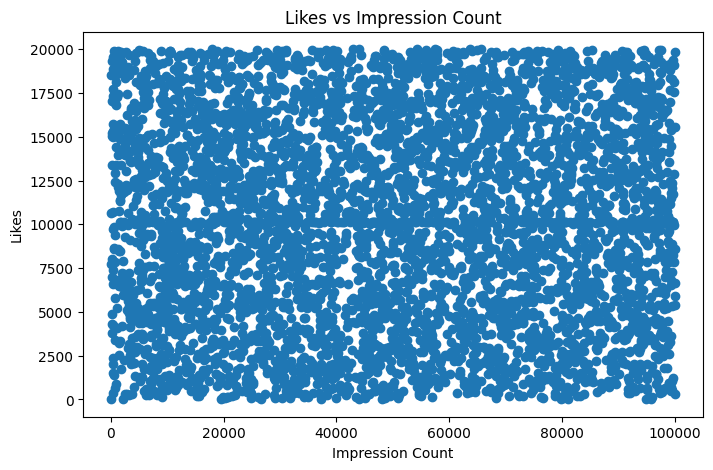

In [59]:
plt.figure(figsize=(8, 5))

plt.scatter(df["impression_count"], df["likes"])

plt.title("Likes vs Impression Count")
plt.xlabel("Impression Count")
plt.ylabel("Likes")

plt.show()

**Line: daily engagement trend**

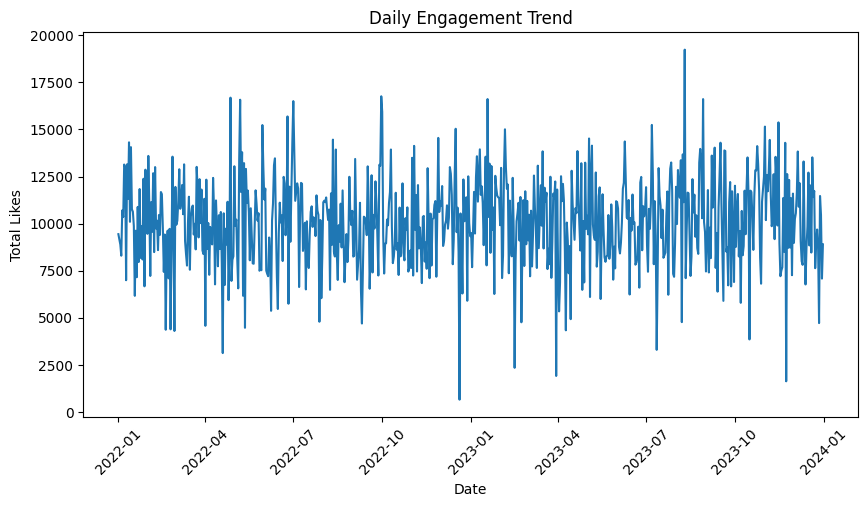

In [60]:
daily_engagement = df.groupby('posted_at')['likes'].mean()
plt.figure(figsize=(10, 5))

plt.plot(daily_engagement.index, daily_engagement.values)

plt.title("Daily Engagement Trend")
plt.xlabel("Date")
plt.ylabel("Total Likes")

plt.xticks(rotation=45)
plt.show()

**Bar: posts by category**

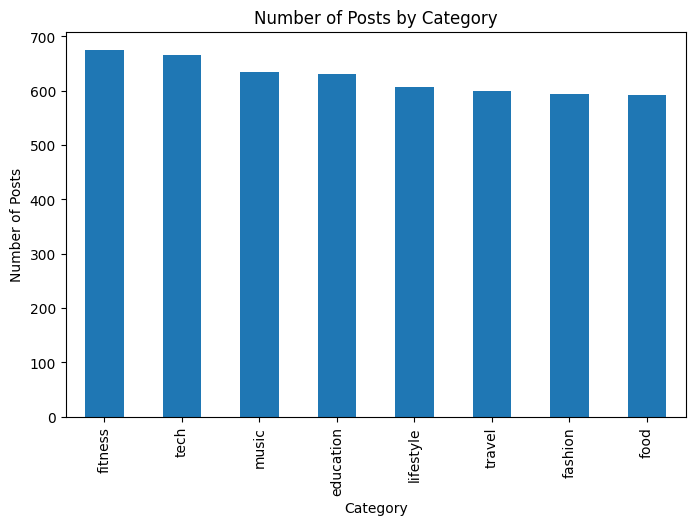

In [61]:
plt.figure(figsize=(8, 5))

df["post_category"].value_counts().plot(kind="bar")

plt.title("Number of Posts by Category")
plt.xlabel("Category")
plt.ylabel("Number of Posts")

plt.show()

**Pie: gender distribution**

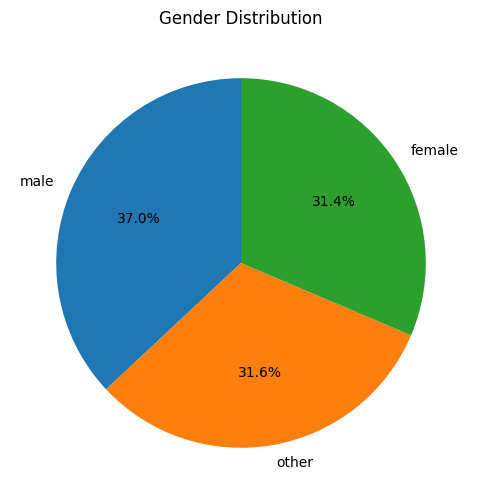

In [62]:
plt.figure(figsize=(6, 6))

df["gender"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Gender Distribution")
plt.ylabel("")

plt.show()

**Histogram: age**

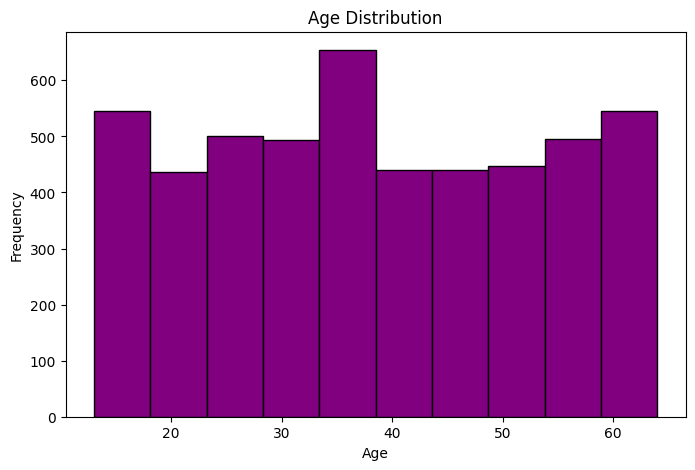

In [63]:
plt.figure(figsize=(8, 5))

plt.hist(df["age"], bins=10,color="purple", edgecolor="black")

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

**Box: engagement rate**


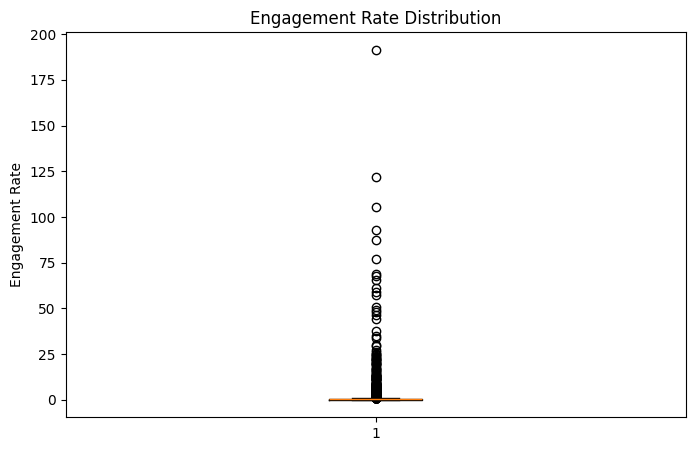

In [64]:
plt.figure(figsize=(8, 5))

plt.boxplot(df["engagement_rate"].dropna())

plt.title("Engagement Rate Distribution")
plt.ylabel("Engagement Rate")

plt.show()

**●Seaborn**

**Count plot: post type**

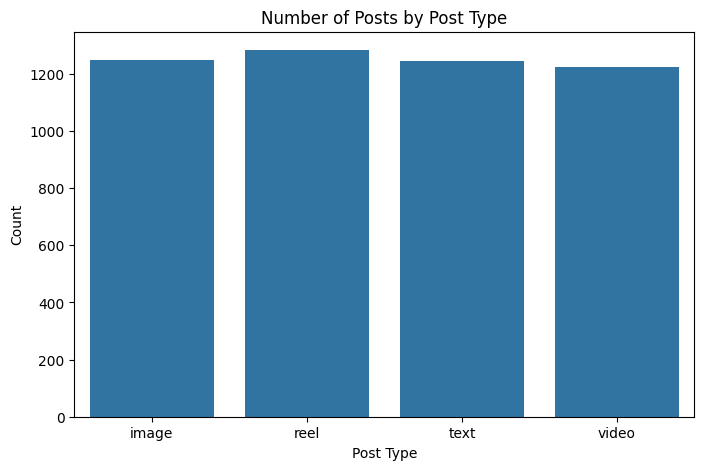

In [65]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="post_type")

plt.title("Number of Posts by Post Type")
plt.xlabel("Post Type")
plt.ylabel("Count")

plt.show()

**Bar plot: avg likes by category**

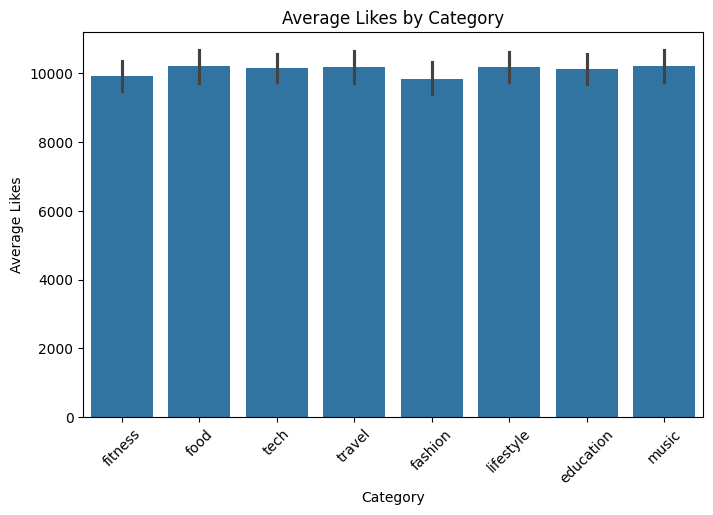

In [66]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="post_category", y="likes")

plt.title("Average Likes by Category")
plt.xlabel("Category")
plt.ylabel("Average Likes")

plt.xticks(rotation=45)
plt.show()

**Violin: followers vs sentiment**

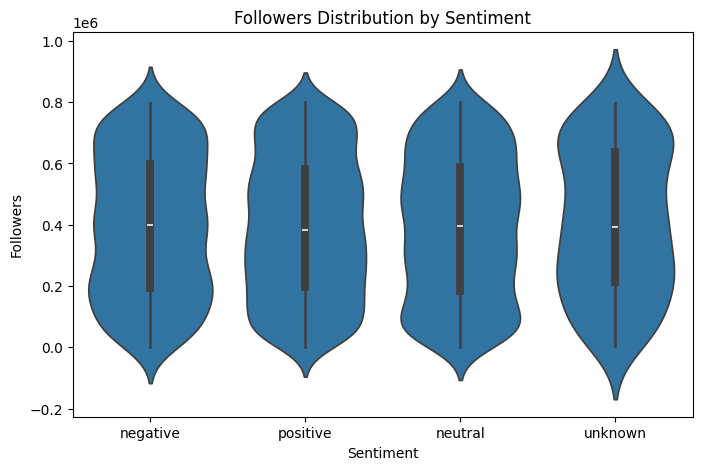

In [67]:
plt.figure(figsize=(8, 5))

sns.violinplot(data=df, x="sentiment", y="follower_count")

plt.title("Followers Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Followers")

plt.show()

**Pair plot: numeric features**

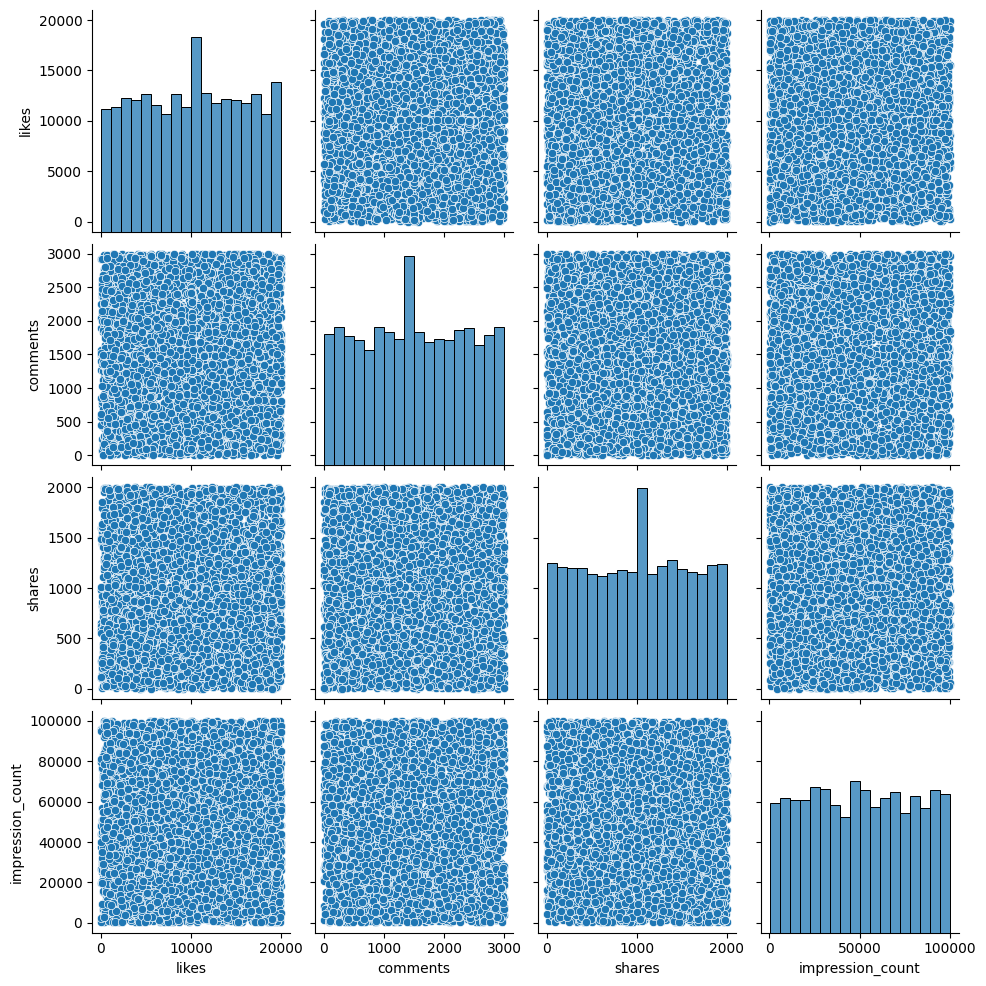

In [68]:
sns.pairplot(
    df[["likes", "comments", "shares", "impression_count"]].dropna()
)

plt.show()

**Heatmap: correlation matrix**

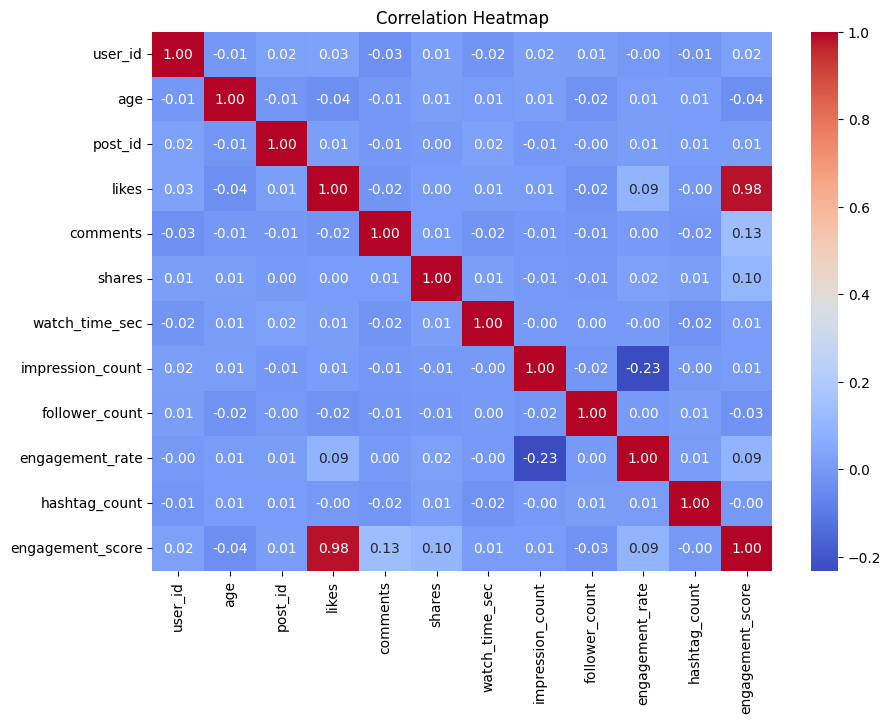

In [69]:
plt.figure(figsize=(10, 7))

correlation = df.select_dtypes(include="number").corr()

sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

**Swarm plot: engagement vs device**

/tmp/ipykernel_2769/3784931597.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(data=df.sample(500, random_state=42), x='device_type', y='engagement_rate', palette='Set1')
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 75.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 76.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 80.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/loca

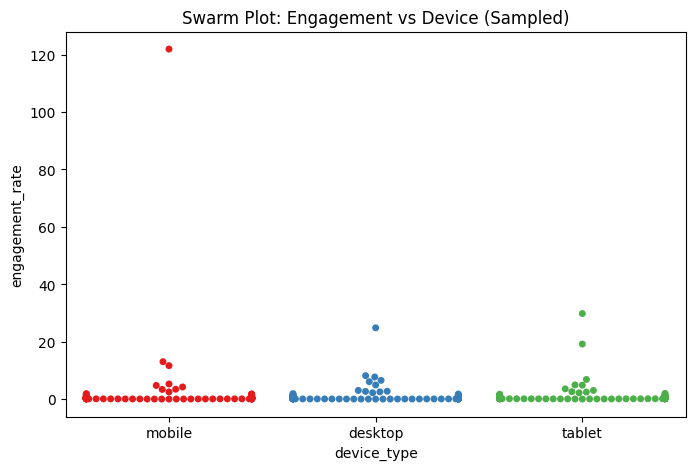

In [79]:
plt.figure(figsize=(8, 5))
sns.swarmplot(data=df.sample(500, random_state=42), x='device_type', y='engagement_rate', palette='Set1')
plt.title('Swarm Plot: Engagement vs Device (Sampled)')
plt.show()

**Plotly (Interactive)**

In [80]:
import plotly.express as px

**Interactive bubble/scatter chart**

In [81]:
fig = px.scatter(
    df,
    x="likes",
    y="comments",
    size="shares",
    color="sentiment",
    title="Social Media Engagement Analysis"
)

fig.show()

In [94]:
display(df)

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,post_hour
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,...,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3,8522.0,0
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,...,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1,16163.0,0
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,...,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1,6161.0,0
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,...,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3,7482.0,0
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,...,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1,16717.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,male,Australia,441541,video,education,16210.0,2013.0,1837.0,...,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2,20060.0,0
4996,22100,38.0,other,UAE,677076,reel,education,16924.0,2734.0,1583.0,...,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2,21241.0,0
4997,67021,63.0,female,USA,273595,text,travel,13487.0,1497.0,167.0,...,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2,15151.0,0
4998,29800,13.0,female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,...,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3,19896.0,0


In [95]:
df.head()


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,post_hour
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,...,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3,8522.0,0
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,...,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1,16163.0,0
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,...,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1,6161.0,0
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,...,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3,7482.0,0
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,...,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1,16717.0,0


In [96]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,post_hour
4995,59500,44.0,male,Australia,441541,video,education,16210.0,2013.0,1837.0,...,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2,20060.0,0
4996,22100,38.0,other,UAE,677076,reel,education,16924.0,2734.0,1583.0,...,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2,21241.0,0
4997,67021,63.0,female,USA,273595,text,travel,13487.0,1497.0,167.0,...,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2,15151.0,0
4998,29800,13.0,female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,...,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3,19896.0,0
4999,73400,54.0,other,Japan,712252,text,travel,14830.0,503.0,1798.0,...,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3,17131.0,0


In [97]:
df.shape

(5000, 22)

In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [99]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


In [100]:
df.duplicated().sum()

np.int64(0)

In [101]:
df.to_csv("final_social_media_dataset.csv", index=False)

In [102]:
from google.colab import files

files.download("final_social_media_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**❖Final Insights should Include following analysis**

**●Content Performance**

**Which post types have highest engagement?**

In [82]:
df.groupby("post_type")["likes"].mean().sort_values(ascending=False)

,likes
post_type,
video,10188.600000
image,10104.865277
text,10100.148193
reel,10037.802416


**Best-performing content category?**

In [84]:
df.groupby("post_category")["engagement_rate"].mean().sort_values(ascending=False)

,engagement_rate
post_category,
food,1.358628
tech,1.160475
lifestyle,1.091019
music,0.888803
fitness,0.865628
education,0.844222
fashion,0.807109
travel,0.702223


**Which countries have highest avg engagement rate? **

In [85]:
df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False)

,engagement_rate
country,
Brazil,1.540704
Australia,1.324339
France,1.146402
UAE,1.112352
Canada,0.916659
UK,0.850966
Japan,0.769623
Germany,0.759000
India,0.655005


**User Trends**

**How age affects engagement**

In [86]:
df.groupby("age")["engagement_rate"].mean().sort_values(ascending=False)

,engagement_rate
age,
24.0,2.897327
55.0,2.599106
51.0,2.397295
48.0,1.675878
50.0,1.552627
41.0,1.540070
35.0,1.521596
47.0,1.402015
42.0,1.350772


**Performance difference for verified accounts**

In [87]:
df.groupby("is_verified")["likes"].mean()

,likes
is_verified,
False,10137.201129
True,9824.533126


**Behavioral Insights**

**Best time of day for impressions**

In [88]:
df["post_hour"] = df["posted_at"].dt.hour

In [89]:
df.groupby("post_hour")["impression_count"].mean().sort_values(ascending=False)

,impression_count
post_hour,
0,50013.7328


**Device type impact on watch time**

In [92]:
df.groupby("device_type")["watch_time_sec"].mean().sort_values(ascending=False)

,watch_time_sec
device_type,
mobile,4087.830760
tablet,3979.736429
desktop,3974.792521


**Sentiment Analysis**

**Which sentiment performs best**

In [93]:
df.groupby("sentiment")[["likes", "comments", "shares"]].mean()

,likes,comments,shares
sentiment,,,
negative,10208.096875,1516.094792,1007.307292
neutral,9923.194499,1528.404060,996.565160
positive,10156.926788,1482.401608,1001.880660
unknown,10544.520000,1453.066667,1055.593333


# Final Insights and Findings

The Social Media Engagement Analytics project helped analyse social media performance using Python, Pandas, NumPy, Matplotlib, Seaborn, and Plotly.

**1. Content Performance:** The analysis identified the post type and category with the highest average engagement. It also helped compare engagement rates across different countries.

**2. User Trends:** The analysis explored the relationship between user age, verified account status, and social media engagement.

**3. User Behaviour:** Posting times and device types were compared to understand their impact on impressions and watch time.

**4. Sentiment Analysis:** Likes, comments, shares, and engagement rates were compared across positive, negative, and neutral sentiment categories.

